# Lab 10 — digits 45
Yusufboy — 240045. **Run all** in Colab and upload both v2 CSV logs when asked.

A uses encoder heading; B uses gyro heading. Both use encoder distance. Two separate route plots show the digits; the error plots explain which segments differed. All positions are robot estimates, not floor measurements.

In [1]:
import numpy as np  # Use arrays and angle formulas.
import pandas as pd  # Read logs and make tables.
import matplotlib.pyplot as plt  # Draw the graphs.
from pathlib import Path  # Check whether the logs are available.
from IPython.display import display  # Show the comparison table.
names = ['YB_W10_D45_A_Wheels_v2.csv', 'YB_W10_D45_B_Gyro_v2.csv']  # Name both logs.
if not all(Path(f).exists() for f in names):  # Upload only if the logs are missing.
    from google.colab import files  # Use Colab's upload button.
    files.upload()  # Select both v2 CSV logs.
logs = [pd.read_csv(f) for f in names]  # Load A first, then B.
X = np.array([0,0,24,24,24,46,76,76,46,46,76])  # Ideal x waypoints in cm.
Y = np.array([0,-30,-30,0,-60,-60,-60,-30,-30,0,0])  # Ideal y waypoints in cm.
dx, dy = np.diff(X), np.diff(Y)  # Changes between consecutive waypoints.
length = np.hypot(dx, dy)  # Ideal lengths of the ten segments.
heading = np.arctan2(dy, dx)  # Ideal headings in radians.
def wrap(a):  # Keep an angle difference within the shortest turn.
    return np.arctan2(np.sin(a), np.cos(a))  # Return an angle between minus pi and pi.

## Offline calculation
The lesson formulas give distance from the average wheel angle and heading from the wheel-angle difference. The gyro calculation subtracts bias and divides by the Lab 9 scale factor. To match the programs, it averages consecutive rates and uses the recorded sensor time interval. Positive and negative rates have separate scale corrections. Both logs have gyro sign +1.

The two offline methods reproduce the logged A and B paths and also give the alternative path for each log.

In [2]:
for name, d in zip(['A', 'B'], logs):  # Process the two logs in the same way.
    assert d.fault.max() == 0 and (d.phase == 3).sum() == 10  # Check successful completion.
    assert (d.gyro_sign == 1).all()  # These logs use the same positive gyro direction.
    d['path'] = (d.theta_r_rad + d.theta_l_rad) * 3.75 / 2  # Encoder distance in cm.
    d['ds'] = d.path.diff().fillna(d.path.iloc[0])  # Distance moved in each interval.
    d['odom'] = (d.theta_r_rad - d.theta_l_rad) * 3.75 / 19.4  # Encoder heading.
    rate = d.gz_mdeg_s / 1000  # Convert gyro rate to degrees per second.
    z0, z1 = rate.shift().fillna(rate.iloc[0]) - d.bias_deg_s, rate - d.bias_deg_s  # Remove bias.
    dt = d.gyro_dt_used_s * (d.t_ms > 10000)  # Use recorded time after calibration.
    positive = ((z0.clip(lower=0) + z1.clip(lower=0)) * dt * np.pi / 360).cumsum()  # Positive angle.
    negative = ((z0.clip(upper=0) + z1.clip(upper=0)) * dt * np.pi / 360).cumsum()  # Negative angle.
    d['gyro'] = positive / d.gain_ccw + negative / d.gain_cw  # Apply Lab 9 scale corrections.
    for method in ['odom', 'gyro']:  # Recalculate x and y using each heading.
        d['x_' + method] = (d.ds * np.cos(d[method])).cumsum()  # Update x from the lesson.
        d['y_' + method] = (d.ds * np.sin(d[method])).cumsum()  # Update y from the lesson.
    own = 'odom' if name == 'A' else 'gyro'  # Select the method actually used on the robot.
    assert np.allclose(d[own], d.course_rad)  # Check the reconstructed heading.
    assert np.allclose(d['x_' + own], d.x_cm) and np.allclose(d['y_' + own], d.y_cm)  # Check position.
    print(f'{name}: offline values match the robot; duration {d.t_ms.iloc[-1]/1000:.2f} s')  # Report result.

A: offline values match the robot; duration 138.15 s
B: offline values match the robot; duration 146.18 s


## Two digit-route graphs
Each panel shows one run. The solid line is its saved robot estimate. The dotted line is the same sensor log recalculated with the other heading method. The dashed black line is the ideal route.

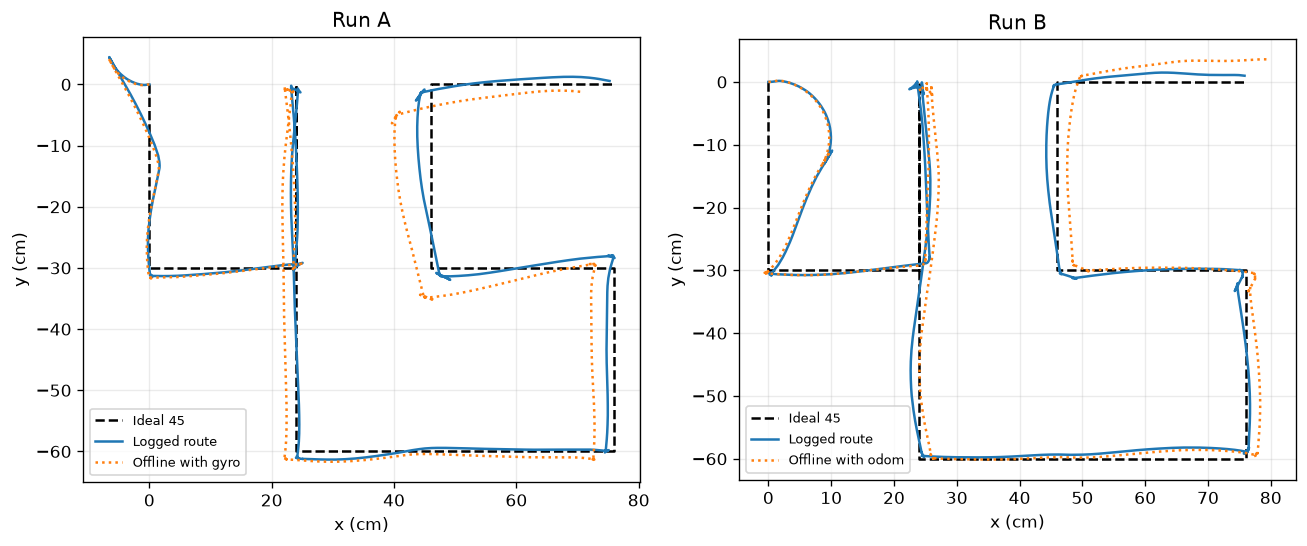

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5))  # Give A and B separate route graphs.
for ax, name, d in zip(axes, ['A', 'B'], logs):  # Draw each run in its own panel.
    other = 'gyro' if name == 'A' else 'odom'  # Choose the alternative heading method.
    ax.plot(X, Y, 'k--', label='Ideal 45')  # Draw the reference digits.
    ax.plot(d.x_cm, d.y_cm, label='Logged route')  # Draw the saved robot estimate.
    ax.plot(d['x_' + other], d['y_' + other], ':', label='Offline with ' + other)  # Compare methods.
    ax.set(title='Run ' + name, xlabel='x (cm)', ylabel='y (cm)')  # Label the graph and units.
    ax.set_aspect('equal', adjustable='box')  # Keep x and y lengths equal on screen.
    ax.grid(alpha=0.25)  # Make distances easier to read.
    ax.legend(fontsize=8)  # Identify the three curves.
plt.tight_layout()  # Keep labels readable.
plt.show()  # Show the two route graphs.

## Comparison table
`i_prev` labels the segment responsible for each interval. `phase_prev == 2` selects driving, excluding pivots from the mean course. Heading error is wrapped and averaged using elapsed time. Segment path includes all signed encoder increments, including turns and stops.

Position error means distance to the nearest point on the current ideal straight segment. This is used only in the error graph.

In [4]:
rows, errors = [], []  # Store table rows and position errors.
for j in range(10):  # Calculate one row for each ideal segment.
    row, positions = [j+1, np.degrees(heading[j]), length[j]], []  # Start with ideal values.
    for d in logs:  # Add A and B results to this row.
        segment = d.i_prev == j+1  # Select the whole segment.
        moving = segment & (d.phase_prev == 2)  # Select driving for heading and position errors.
        weights = d.t_ms.diff().fillna(0)[moving]  # Use actual elapsed time as averaging weights.
        error = np.average(wrap(d.course_rad[moving] - heading[j]), weights=weights)  # Mean heading error.
        path = d.ds[segment].sum()  # Sum encoder distance increments for this segment.
        row += [np.degrees(heading[j]+error), np.degrees(error), path, path-length[j]]  # Add measured values.
        px, py = d.x_cm[moving]-X[j], d.y_cm[moving]-Y[j]  # Position relative to segment start.
        fraction = np.clip((px*dx[j]+py*dy[j])/length[j]**2, 0, 1)  # Find the nearest point on the segment.
        distance = np.hypot(px-fraction*dx[j], py-fraction*dy[j])  # Distance to the ideal stroke in cm.
        positions.append(np.average(distance, weights=weights))  # Save mean position error.
    rows.append(row)  # Save this segment's comparison.
    errors.append(positions)  # Save this segment's A and B position errors.
columns = ['Segment','Reference deg','Reference cm','Course A','Error A deg','Path A','Error A cm','Course B','Error B deg','Path B','Error B cm']  # Label columns.
table = pd.DataFrame(rows, columns=columns)  # Make the comparison table.
total = ['Summary', '', length.sum()]  # Start the summary row.
for name, d in zip(['A', 'B'], logs):  # Summarize each run.
    mean_error = table['Error '+name+' deg'].abs().mean()  # Mean absolute segment course error.
    path = d.ds.sum()  # Total signed encoder distance.
    total += ['', mean_error, path, path-length.sum()]  # Add totals to the summary row.
    final = np.hypot(d.x_cm.iloc[-1]-X[-1], d.y_cm.iloc[-1]-Y[-1])  # Final estimated position error.
    angle = np.degrees(wrap(d.course_rad.iloc[-1]-heading[-1]))  # Final heading error.
    print(f'{name}: course MAE {mean_error:.2f} deg; path error {100*(path/length.sum()-1):+.2f}%; final {final:.2f} cm, {angle:+.2f} deg')  # Print summary.
display(pd.concat([table, pd.DataFrame([total], columns=columns)]).round(2))  # Show all rows and totals.

A: course MAE 3.74 deg; path error -0.18%; final 0.95 cm, -11.79 deg
B: course MAE 4.80 deg; path error +2.17%; final 1.01 cm, -9.19 deg


,Segment,Reference deg,Reference cm,Course A,Error A deg,Path A,Error A cm,Course B,Error B deg,Path B,Error B cm
0,1,-90.0,30.0,-77.865072,12.13,28.50,-1.50,-117.200383,-27.20,38.98,8.98
1,2,0.0,24.0,3.895484,3.90,24.51,0.51,2.765679,2.77,24.54,0.54
2,3,90.0,30.0,90.192169,0.19,29.49,-0.51,93.985306,3.99,29.03,-0.97
3,4,-90.0,60.0,-90.287896,-0.29,60.05,0.05,-89.150306,0.85,59.07,-0.93
4,5,0.0,22.0,4.106535,4.11,22.32,0.32,-0.164314,-0.16,22.15,0.15
5,6,0.0,30.0,-1.653193,-1.65,29.09,-0.91,1.064513,1.06,29.68,-0.32
6,7,90.0,30.0,87.887291,-2.11,30.79,0.79,84.92853,-5.07,28.86,-1.14
7,8,180.0,30.0,177.232971,-2.77,30.14,0.14,176.357236,-3.64,29.75,-0.25
8,9,90.0,30.0,82.858168,-7.14,30.27,0.27,90.27178,0.27,30.40,0.40
9,10,0.0,30.0,3.123075,3.12,30.27,0.27,3.032988,3.03,30.40,0.40


## Segment errors
Heading error tells us whether each stroke points the right way. Position error tells us how far its estimate is from the intended stroke. This shows why a small final position error can hide an earlier deviation.

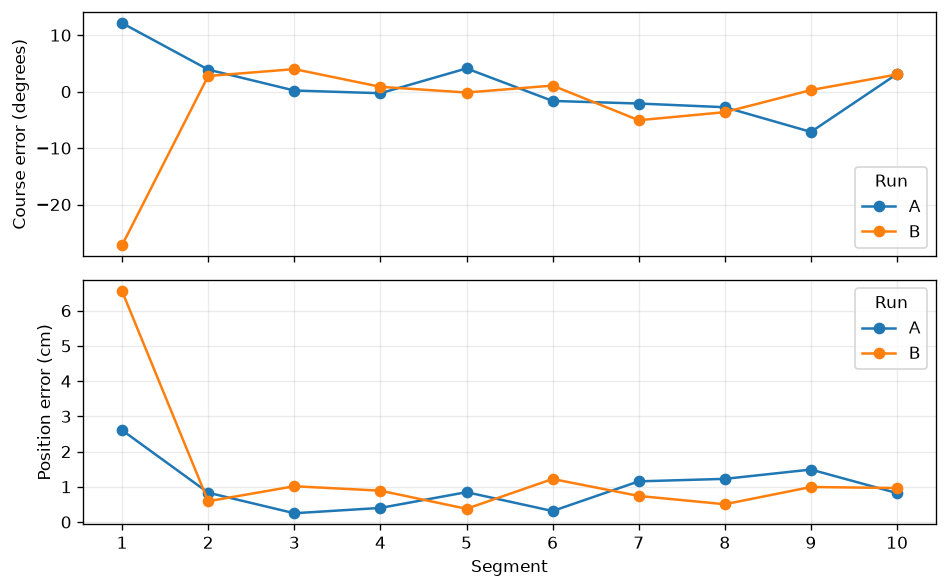

In [5]:
fig, axes = plt.subplots(2, 1, figsize=(8, 5), sharex=True)  # Keep the two existing error plots.
for k, name in enumerate(['A', 'B']):  # Plot both runs for comparison.
    axes[0].plot(range(1,11), table['Error '+name+' deg'], 'o-', label=name)  # Mean segment heading errors.
    axes[1].plot(range(1,11), np.array(errors)[:, k], 'o-', label=name)  # Mean distance to the ideal stroke.
axes[0].set_ylabel('Course error (degrees)')  # State heading-error units.
axes[1].set(ylabel='Position error (cm)', xlabel='Segment', xticks=range(1,11))  # Label position error and segment number.
for ax in axes:  # Apply the same formatting to both panels.
    ax.grid(alpha=0.25)  # Help read the error values.
    ax.legend(title='Run')  # Identify A and B.
plt.tight_layout()  # Avoid label overlap.
plt.show()  # Display the error plots.

## Conclusion
Both runs completed all 10 segments. A had smaller mean heading error (**3.74° vs 4.80°**) and total path error (**−0.18% vs +2.17%**). B had smaller final heading error (**−9.19° vs −11.79°**).

The largest deviation was on the first segment, especially in B; later errors did not continually grow. Offline results matched the robot estimates. The logs alone cannot tell whether slip, wheel spacing, bias or scale error dominated.

Next lesson: combine encoder and gyro heading with the complementary filter.